#**Практическое задание №1**

Установка необходимых пакетов:

In [1]:
!pip install -q tqdm
!pip install --upgrade --no-cache-dir gdown


[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip



[notice] A new release of pip is available: 23.2.1 -> 26.3
[notice] To update, run: python.exe -m pip install --upgrade pip


Монтирование Вашего Google Drive к текущему окружению:

**ТУТ ИЗМЕНИЛ, ПОТОМУ ЧТО В VS CODE ДЕЛАЛ**

#LBL1

In [2]:
try:
    from google.colab import drive
    drive.mount('/content/drive', force_remount=True)
    my_dir = '/content/drive/MyDrive/spec_curs_1'
except ModuleNotFoundError:
    my_dir = './papka_with_weights'

from pathlib import Path
Path(my_dir).mkdir(parents=True, exist_ok=True) #проверить потом как в колабе работать будет

Константы, которые пригодятся в коде далее, и ссылки (gdrive идентификаторы) на предоставляемые наборы данных:

In [3]:
EVALUATE_ONLY = False
TEST_ON_LARGE_DATASET = True
TISSUE_CLASSES = ('ADI', 'BACK', 'DEB', 'LYM', 'MUC', 'MUS', 'NORM', 'STR', 'TUM')
DATASETS_LINKS = {
    'train': '1XtQzVQ5XbrfxpLHJuL0XBGJ5U7CS-cLi',
    'train_small': '1qd45xXfDwdZjktLFwQb-et-mAaFeCzOR',
    'train_tiny': '1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui',
    'test': '1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr',
    'test_small': '1wbRsog0n7uGlHIPGLhyN-PMeT2kdQ2lI',
    'test_tiny': '1viiB0s041CNsAK4itvX8PnYthJ-MDnQc',
    'best': '19GLXhRISwhUdFffmV1rrFY5P09ObMEPN'
}


Импорт необходимых зависимостей:

In [4]:
from pathlib import Path
import numpy as np
from typing import List
from tqdm.notebook import tqdm
from time import sleep
from PIL import Image
import IPython.display
from sklearn.metrics import balanced_accuracy_score
import gdown

---
### Класс Dataset

Предназначен для работы с наборами данных, обеспечивает чтение изображений и соответствующих меток, а также формирование пакетов (батчей).

In [6]:
class Dataset:

    def __init__(self, name):
        self.name = name
        self.is_loaded = False
        url = f"https://drive.google.com/uc?export=download&confirm=pbef&id={DATASETS_LINKS[name]}"
        output = f'{name}.npz'
        gdown.download(url, output, quiet=False)
        print(f'Loading dataset {self.name} from npz.')
        np_obj = np.load(f'{name}.npz')
        self.images = np_obj['data']
        self.labels = np_obj['labels']
        self.n_files = self.images.shape[0]
        self.is_loaded = True
        print(f'Done. Dataset {name} consists of {self.n_files} images.')

    def image(self, i):
        # read i-th image in dataset and return it as numpy array
        if self.is_loaded:
            return self.images[i, :, :, :]

    def images_seq(self, n=None):
        # sequential access to images inside dataset (is needed for testing)
        for i in range(self.n_files if not n else n):
            yield self.image(i)

    def random_image_with_label(self):
        # get random image with label from dataset
        i = np.random.randint(self.n_files)
        return self.image(i), self.labels[i]

    def random_batch_with_labels(self, n):
        # create random batch of images with labels (is needed for training)
        indices = np.random.choice(self.n_files, n)
        imgs = [self.image(i) for i in indices]
        labels = np.array([self.labels[i] for i in indices])
        return np.stack(imgs), labels

    def image_with_label(self, i: int):
        # return i-th image with label from dataset
        return self.image(i), self.labels[i]


### Пример использвания класса Dataset
Загрузим обучающий набор данных, получим произвольное изображение с меткой. После чего визуализируем изображение, выведем метку. В будущем, этот кусок кода можно закомментировать или убрать.

Downloading...
From (original): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui
From (redirected): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui&confirm=t&uuid=7938fb1d-f13c-406d-ba51-c48212a3c7d8
To: d:\кодики\Python codes\spec_curs_1\train_tiny.npz
100%|██████████| 105M/105M [00:02<00:00, 35.0MB/s] 


Loading dataset train_tiny from npz.
Done. Dataset train_tiny consists of 900 images.

Got numpy array of shape (224, 224, 3), and label with code 7.
Label code corresponds to STR class.


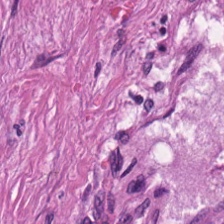

In [7]:
d_train_tiny = Dataset('train_tiny')

img, lbl = d_train_tiny.random_image_with_label()
print()
print(f'Got numpy array of shape {img.shape}, and label with code {lbl}.')
print(f'Label code corresponds to {TISSUE_CLASSES[lbl]} class.')

pil_img = Image.fromarray(img)
IPython.display.display(pil_img)

### Обёртка над Dataset для использования с PyTorch

In [ ]:
# ============================================================
# (Опционально) Обёртка над Dataset для использования с PyTorch
# ============================================================

# ВНИМАНИЕ:
# Этот код нужен только тем, кто хочет решать задание с помощью PyTorch.
# Он показывает, как "подключить" наш Dataset к torch.utils.data.DataLoader.

try:
    import torch
    from torch.utils.data import Dataset as TorchDataset, DataLoader
    import torchvision.transforms as T
    from PIL import Image

    class HistologyTorchDataset(TorchDataset):
        """
        Обёртка над Dataset для использования с PyTorch.

        base_dataset: экземпляр Dataset('train'), Dataset('train_small'), etc.
        transform:    функция/объект, преобразующий изображение (PIL.Image -> torch.Tensor).

        """
        def __init__(self, base_dataset, transform=None):
            self.base = base_dataset
            # Минимальный transform по умолчанию:
            # np.uint8 [0, 255] -> float32 [0.0, 1.0]
            self.transform = transform or T.ToTensor()

        def __len__(self):
            # Размер датасета
            return len(self.base.images)

        def __getitem__(self, idx):
            """
            Возвращает (image_tensor, label) для PyTorch.
            image_tensor: torch.Tensor формы [3, H, W]
            label: int
            """
            img, label = self.base.image_with_label(idx)  # img: np.ndarray (H, W, 3)
            img = Image.fromarray(img)                    # в PIL.Image
            img = self.transform(img)                     # в torch.Tensor
            return img, int(label)

except ImportError:
    HistologyTorchDataset = None
    print("PyTorch / torchvision не найдены. Обёртка HistologyTorchDataset недоступна.")


### Пример использвания класса HistologyTorchDataset

In [ ]:
if "HistologyTorchDataset" not in globals() or HistologyTorchDataset is None:
    print("PyTorch не установлен или обёртка недоступна — пример пропущен.")
else:
    print("Пример использования PyTorch-обёртки над Dataset")

    base_train = Dataset('train_tiny')

    # Создаём PyTorch-совместимый датасет
    train_ds = HistologyTorchDataset(base_train)

    # DataLoader автоматически создаёт батчи и перемешивает данные
    from torch.utils.data import DataLoader
    train_loader = DataLoader(train_ds, batch_size=8, shuffle=True)

    # Берём один батч и выводим информацию
    images_batch, labels_batch = next(iter(train_loader))

    print("Форма батча изображений:", tuple(images_batch.shape))  # [batch, 3, 224, 224]
    print("Форма батча меток:", tuple(labels_batch.shape))        # [batch]
    print("Пример меток:", labels_batch[:10].tolist())

    print("Тип images_batch:", type(images_batch))
    print("Тип labels_batch:", type(labels_batch))


---
### Класс Metrics

Реализует метрики точности, используемые для оценивания модели:
1. точность,
2. сбалансированную точность.

In [8]:
class Metrics:

    @staticmethod
    def accuracy(gt: List[int], pred: List[int]):
        assert len(gt) == len(pred), 'gt and prediction should be of equal length'
        return sum(int(i[0] == i[1]) for i in zip(gt, pred)) / len(gt)

    @staticmethod
    def accuracy_balanced(gt: List[int], pred: List[int]):
        return balanced_accuracy_score(gt, pred)

    @staticmethod
    def print_all(gt: List[int], pred: List[int], info: str):
        print(f'metrics for {info}:')
        print('\t accuracy {:.4f}:'.format(Metrics.accuracy(gt, pred)))
        print('\t balanced accuracy {:.4f}:'.format(Metrics.accuracy_balanced(gt, pred)))

---
### Класс Model

Класс, хранящий в себе всю информацию о модели.

Вам необходимо реализовать методы save, load для сохранения и загрузки модели. Особенно актуально это будет во время тестирования на дополнительных наборах данных.


> *Пожалуйста, убедитесь, что сохранение и загрузка модели работает корректно. Для этого обучите модель, протестируйте, сохраните ее в файл, перезапустите среду выполнения, загрузите обученную модель из файла, вновь протестируйте ее на тестовой выборке и убедитесь в том, что получаемые метрики совпадают с полученными для тестовой выборки ранее.*


Также, Вы можете реализовать дополнительные функции, такие как:
1. валидацию модели на части обучающей выборки;
2. использование кроссвалидации;
3. автоматическое сохранение модели при обучении;
4. загрузку модели с какой-то конкретной итерации обучения (если используется итеративное обучение);
5. вывод различных показателей в процессе обучения (например, значение функции потерь на каждой эпохе);
6. построение графиков, визуализирующих процесс обучения (например, график зависимости функции потерь от номера эпохи обучения);
7. автоматическое тестирование на тестовом наборе/наборах данных после каждой эпохи обучения (при использовании итеративного обучения);
8. автоматический выбор гиперпараметров модели во время обучения;
9. сохранение и визуализацию результатов тестирования;
10. Использование аугментации и других способов синтетического расширения набора данных (дополнительным плюсом будет обоснование необходимости и обоснование выбора конкретных типов аугментации)
11. и т.д.

Полный список опций и дополнений приведен в презентации с описанием задания.

При реализации дополнительных функций допускается добавление параметров в существующие методы и добавление новых методов в класс модели.


In [9]:
class Model:

    def __init__(self):
        # todo
        pass

    def save(self, name: str):
        # todo: сохраните веса вашей модели.
        # Пример уже рабочий: он пишет npz на Google Drive, а load читает тот же файл.
        path = f'{my_dir}/{name}.npz'
        data = np.asarray(
            self.weights if getattr(self, 'weights', None) is not None
            else np.array([1, 2, 3, 4, 5], dtype=np.float32)
        )
        np.savez(path, data=data)
        print(f'Модель сохранена в {path}.')
        print('Чтобы сдать файл ссылкой, откройте к нему доступ и вставьте id в load().')

    def load(self, name: str):
        # todo: если сдаёте модель ссылкой, замените None на id вашего файла.
        # Пока id не указан, читается файл, который save записал на примонтированный Drive.
        name_to_id_dict = {
            'best': None,
        }
        file_id = name_to_id_dict.get(name)
        output = f'{name}.npz'
        if file_id:
            gdown.download(id=file_id, output=output, quiet=False)
            path = output
        else:
            path = f'{my_dir}/{output}'
            if not Path(path).exists():
                raise FileNotFoundError(
                    f'Не найден {path}. Вызовите save("{name}") при смонтированном Google Drive '
                    f'или укажите id файла в name_to_id_dict внутри load().'
                )
        np_obj = np.load(path)
        self.weights = np_obj['data']
        print(self.weights)

    def train(self, dataset: Dataset):
        # you can add some plots for better visualization,
        # you can add model autosaving during training,
        # etc.
        print(f'training started')
        # to-do
        sleep(2)
        print(f'training done')
        pass

    def test_on_dataset(self, dataset: Dataset, limit=None):
        # you can upgrade this code if you want to speed up testing using batches
        predictions = []
        n = dataset.n_files if not limit else int(dataset.n_files * limit)
        for img in tqdm(dataset.images_seq(n), total=n):
            predictions.append(self.test_on_image(img, 2026))
        return predictions

    def test_on_image(self, img: np.ndarray, submission_year: int):
        # todo: replace this code
        prediction = int(np.random.randint(9))
        return prediction


ТУТ МОЯ МОДЕЛ

#LBL2

In [9]:
import joblib

class Model:
    def __init__(self):
        self.resnet = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V1)
        self.resnet.fc = torch.nn.Identity()
        self.svm = None

    def train(self, dataset: Dataset):
        print('training started')
        features_8 = get_features_8(self.resnet, dataset.images)
        X_parts = []
        y_parts = []
        for j in range(8):
            X_parts.append(features_8[j])
            y_parts.append(dataset.labels)
        X_aug = np.concatenate(X_parts)
        y_aug = np.concatenate(y_parts)
        self.svm = SVC(C=10, cache_size=4000).fit(X_aug, y_aug)
        print('training done')

    def save(self, name: str):
        path = f'{my_dir}/{name}.joblib'
        joblib.dump(self.svm, path)
        print(f'Модель сохранена в {path}.')
        print('Чтобы сдать файл ссылкой, откройте к нему доступ и вставьте id в load().')

    def load(self, name: str):
        name_to_id_dict = {'best': '19GLXhRISwhUdFffmV1rrFY5P09ObMEPN'}
        file_id = name_to_id_dict.get(name)
        output = f'{name}.joblib'
        if file_id:
            gdown.download(id=file_id, output=output, quiet=False)
            path = output
        else:
            path = f'{my_dir}/{output}'
            if not Path(path).exists():
                raise FileNotFoundError(
                    f'Не найден {path}. Вызовите save("{name}") при смонтированном Google Drive '
                    f'или укажите id файла в name_to_id_dict внутри load().'
                )
        self.svm = joblib.load(path)

    def predict_batch(self, images):
        features_8 = get_features_8(self.resnet, images)
        scores = 0
        for j in range(8):
            scores = scores + self.svm.decision_function(features_8[j])
        classes = self.svm.classes_[scores.argmax(1)]
        return [int(c) for c in classes]

    def test_on_image(self, img: np.ndarray, submission_year: int):
        return self.predict_batch(img[np.newaxis])[0]

    def test_on_dataset(self, dataset: Dataset, limit=None):
        n = dataset.n_files if not limit else int(dataset.n_files * limit)
        predicts = []
        batch = []
        for img in tqdm(dataset.images_seq(n), total=n):
            batch.append(img)
            if len(batch) == 256:
                predicts.extend(self.predict_batch(np.stack(batch)))
                batch = []
        if len(batch) > 0:
            predicts.extend(self.predict_batch(np.stack(batch)))
        return predicts

**ТУТ НАЧАЛО МОЕГО КОДА**

#LBL3

In [10]:
import cv2
import torch, torchvision
from scipy.special import softmax
from sklearn.model_selection import StratifiedKFold, cross_val_predict
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import Normalizer, StandardScaler
from sklearn.svm import SVC

def rotate(mass_image, angle):
    a = mass_image.shape[1]
    b = mass_image.shape[2]
    matrix = cv2.getRotationMatrix2D(((b - 1) / 2, (a - 1)/ 2), angle, 1)
    result = np.zeros_like(mass_image)
    for i in range(len(mass_image)):
        result[i] = cv2.warpAffine(mass_image[i], matrix, (b, a))
    return result

def flip(images):
    return images[:, :, ::-1]

def get_features(cnn, mass_image):
    normalize = torchvision.transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])
    cnn = cnn.eval().cuda()
    result = []
    for i in range(0, len(mass_image), 128):
        batch = torch.from_numpy(mass_image[i:i + 128]).cuda()
        batch = batch.permute(0, 3, 1, 2) / 255
        batch = normalize(batch)
        with torch.no_grad(): #resnet не обучаем, поэтому не надо считать градиенты
            features = cnn(batch)
        result.append(features.cpu().numpy()) #на проц переносим, т.к. scikit на нем работает
    return np.concatenate(result)

def get_features_8(cnn, mass_image):
    result = []
    for i in (0, 90, 180, 270):
        result.append(get_features(cnn, rotate(mass_image, i)))
    flipped = flip(mass_image)
    for i in (0, 90, 180, 270):
        result.append(get_features(cnn, rotate(flipped, i)))
    return np.stack(result)

#LBL4

In [10]:
tiny_train = Dataset('train_tiny')
tiny_test = Dataset('test_tiny')
X_train_tiny = tiny_train.images
y_train_tiny = tiny_train.labels
X_test_tiny = tiny_test.images
y_test_tiny =  tiny_test.labels

resnet = torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1)
resnet.fc = torch.nn.Identity() #убираем последний слой. А точнее, делаем так, чтобы последний слой ничего не делал. То есть он выдает то же самое, что и предпоследний
train_tiny_after_cnn = get_features(resnet, X_train_tiny)
test_tiny_after_cnn = get_features(resnet, X_test_tiny)
for i in ('euclidean', 'cosine'):
    for j in range(1, 11):
        knn = KNeighborsClassifier(n_neighbors=j, weights='distance', metric=i).fit(train_tiny_after_cnn, y_train_tiny)
        pred = knn.predict(test_tiny_after_cnn)
        acc = Metrics.accuracy(y_test_tiny, pred)
        balance_acc = Metrics.accuracy_balanced(y_test_tiny, pred)
        print(f'tiny KNN k={j} {i} Accuracy {acc} Balance_accuracy {balance_acc}')

Downloading...
From (original): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui
From (redirected): https://drive.google.com/uc?id=1I-2ZOuXLd4QwhZQQltp817Kn3J0Xgbui&confirm=t&uuid=ce66a75f-5950-43b7-8eaa-c9b8154a523c
To: d:\кодики\Python codes\spec_curs_1\train_tiny.npz
100%|██████████| 105M/105M [00:03<00:00, 28.8MB/s] 


Loading dataset train_tiny from npz.
Done. Dataset train_tiny consists of 900 images.


Downloading...
From: https://drive.google.com/uc?id=1viiB0s041CNsAK4itvX8PnYthJ-MDnQc
To: d:\кодики\Python codes\spec_curs_1\test_tiny.npz
100%|██████████| 10.6M/10.6M [00:00<00:00, 17.2MB/s]


Loading dataset test_tiny from npz.
Done. Dataset test_tiny consists of 90 images.
tiny KNN k=1 euclidean Accuracy 0.8444444444444444 Balance_accuracy 0.8444444444444444
tiny KNN k=2 euclidean Accuracy 0.8444444444444444 Balance_accuracy 0.8444444444444444
tiny KNN k=3 euclidean Accuracy 0.9 Balance_accuracy 0.9000000000000001
tiny KNN k=4 euclidean Accuracy 0.9222222222222223 Balance_accuracy 0.9222222222222223
tiny KNN k=5 euclidean Accuracy 0.9111111111111111 Balance_accuracy 0.911111111111111
tiny KNN k=6 euclidean Accuracy 0.9 Balance_accuracy 0.8999999999999999
tiny KNN k=7 euclidean Accuracy 0.8777777777777778 Balance_accuracy 0.8777777777777778
tiny KNN k=8 euclidean Accuracy 0.8666666666666667 Balance_accuracy 0.8666666666666667
tiny KNN k=9 euclidean Accuracy 0.8777777777777778 Balance_accuracy 0.8777777777777778
tiny KNN k=10 euclidean Accuracy 0.8555555555555555 Balance_accuracy 0.8555555555555556
tiny KNN k=1 cosine Accuracy 0.8333333333333334 Balance_accuracy 0.8333333333

#LBL5

In [11]:
small_train = Dataset('train_small')
X_train_small = small_train.images
y_train_small = small_train.labels
train_small_after_cnn = get_features(resnet, X_train_small)
folds = list(StratifiedKFold(n_splits=5, shuffle=True, random_state=42).split(train_small_after_cnn, y_train_small))

def fold_scores(pred):
    mass_acc = []
    mass_balance_acc = []
    for i in range(len(folds)):
        val_index = folds[i][1]
        mass_acc.append(Metrics.accuracy(y_train_small[val_index], pred[val_index]))
        mass_balance_acc.append(Metrics.accuracy_balanced(y_train_small[val_index], pred[val_index]))
    return np.mean(mass_acc), np.mean(mass_balance_acc)

for i in ('euclidean', 'cosine'):
    for j in range(1, 11):
        clf = KNeighborsClassifier(n_neighbors=j, metric=i, weights='distance')
        pred = cross_val_predict(clf, train_small_after_cnn, y_train_small, cv=folds)
        acc, balance_acc = fold_scores(pred)
        print(f'KNN k={j} {i} Accuracy {acc} Balance_accuracy {balance_acc}')

Downloading...
From (original): https://drive.google.com/uc?id=1qd45xXfDwdZjktLFwQb-et-mAaFeCzOR
From (redirected): https://drive.google.com/uc?id=1qd45xXfDwdZjktLFwQb-et-mAaFeCzOR&confirm=t&uuid=bcb31d4c-b72a-4cc3-907b-5ca81acb3fa3
To: d:\кодики\Python codes\spec_curs_1\train_small.npz
100%|██████████| 841M/841M [00:29<00:00, 28.3MB/s] 


Loading dataset train_small from npz.
Done. Dataset train_small consists of 7200 images.
KNN k=1 euclidean Accuracy 0.905 Balance_accuracy 0.905
KNN k=2 euclidean Accuracy 0.905 Balance_accuracy 0.905
KNN k=3 euclidean Accuracy 0.9143055555555556 Balance_accuracy 0.9143055555555556
KNN k=4 euclidean Accuracy 0.9204166666666668 Balance_accuracy 0.9204166666666665
KNN k=5 euclidean Accuracy 0.9177777777777777 Balance_accuracy 0.9177777777777777
KNN k=6 euclidean Accuracy 0.9169444444444445 Balance_accuracy 0.9169444444444445
KNN k=7 euclidean Accuracy 0.9144444444444444 Balance_accuracy 0.9144444444444446
KNN k=8 euclidean Accuracy 0.915 Balance_accuracy 0.9149999999999998
KNN k=9 euclidean Accuracy 0.913888888888889 Balance_accuracy 0.913888888888889
KNN k=10 euclidean Accuracy 0.9134722222222222 Balance_accuracy 0.9134722222222222
KNN k=1 cosine Accuracy 0.9083333333333334 Balance_accuracy 0.9083333333333334
KNN k=2 cosine Accuracy 0.9083333333333334 Balance_accuracy 0.9083333333333334

#LBL6

In [12]:
for i in (1, 3, 10, 30, 100):
    clf = make_pipeline(StandardScaler(), SVC(C=i))
    pred = cross_val_predict(clf, train_small_after_cnn, y_train_small, cv=folds)
    acc, balance_acc = fold_scores(pred)
    print(f'SVM StandardScaler C={i} Accuracy {acc} Balance_accuracy {balance_acc}')

for i in (1, 3, 10, 30, 100):
    clf = make_pipeline(Normalizer(), SVC(C=i))
    pred = cross_val_predict(clf, train_small_after_cnn, y_train_small, cv=folds)
    acc, balance_acc = fold_scores(pred)
    print(f'SVM Normalizer C={i} Accuracy {acc} Balance_accuracy {balance_acc}')

for i in (1, 3, 10, 30, 100):
    pred = cross_val_predict(SVC(C=i), train_small_after_cnn, y_train_small, cv=folds)
    acc, balance_acc = fold_scores(pred)
    print(f'SVM C={i} Accuracy {acc} Balance_accuracy {balance_acc}')

SVM StandardScaler C=1 Accuracy 0.9334722222222223 Balance_accuracy 0.9334722222222223
SVM StandardScaler C=3 Accuracy 0.9409722222222223 Balance_accuracy 0.9409722222222223
SVM StandardScaler C=10 Accuracy 0.9411111111111111 Balance_accuracy 0.9411111111111111
SVM StandardScaler C=30 Accuracy 0.9415277777777777 Balance_accuracy 0.9415277777777777
SVM StandardScaler C=100 Accuracy 0.9415277777777777 Balance_accuracy 0.9415277777777777
SVM Normalizer C=1 Accuracy 0.9348611111111111 Balance_accuracy 0.9348611111111111
SVM Normalizer C=3 Accuracy 0.943888888888889 Balance_accuracy 0.943888888888889
SVM Normalizer C=10 Accuracy 0.945 Balance_accuracy 0.945
SVM Normalizer C=30 Accuracy 0.9444444444444444 Balance_accuracy 0.9444444444444444
SVM Normalizer C=100 Accuracy 0.9444444444444444 Balance_accuracy 0.9444444444444444
SVM C=1 Accuracy 0.9338888888888889 Balance_accuracy 0.9338888888888889
SVM C=3 Accuracy 0.943611111111111 Balance_accuracy 0.943611111111111
SVM C=10 Accuracy 0.94583333

#LBL7

In [13]:
knn = KNeighborsClassifier(n_neighbors=5, metric='cosine', weights='distance')
svm = SVC(C=10)
svm_score_cv = cross_val_predict(svm, train_small_after_cnn, y_train_small, cv=folds, method='decision_function')
knn_prob_cv = cross_val_predict(knn, train_small_after_cnn, y_train_small, cv=folds, method='predict_proba')
for i in (0.1, 0.3, 0.5, 0.7, 0.9, 1): #тут 0.9 лучше всего подошел, поэтому его используем после цикла
    pred = (i * softmax(svm_score_cv, axis=1) + (1 - i) * knn_prob_cv).argmax(1)
    acc, balance_acc = fold_scores(pred)
    print(f'a={i} Accuracy {acc} Balance_accuracy {balance_acc}')

a = 0.9
small_test = Dataset('test_small')
X_test_small = small_test.images
y_test_small = small_test.labels
test_small_after_cnn = get_features(resnet, X_test_small)
knn.fit(train_small_after_cnn, y_train_small)
svm.fit(train_small_after_cnn, y_train_small)
knn_prob_test = knn.predict_proba(test_small_after_cnn)
svm_prob_test = softmax(svm.decision_function(test_small_after_cnn), axis=1)
Metrics.print_all(y_test_small, knn_prob_test.argmax(1), 'test_small KNN')
Metrics.print_all(y_test_small, svm_prob_test.argmax(1), 'test_small SVM')
Metrics.print_all(y_test_small, (a * svm_prob_test + (1 - a) * knn_prob_test).argmax(1), 'test_small KNN+SVM')

a=0.1 Accuracy 0.9272222222222222 Balance_accuracy 0.9272222222222222
a=0.3 Accuracy 0.9352777777777778 Balance_accuracy 0.9352777777777778
a=0.5 Accuracy 0.9409722222222221 Balance_accuracy 0.9409722222222221
a=0.7 Accuracy 0.9463888888888888 Balance_accuracy 0.9463888888888888
a=0.9 Accuracy 0.9466666666666667 Balance_accuracy 0.9466666666666669
a=1 Accuracy 0.9458333333333332 Balance_accuracy 0.9458333333333332


Downloading...
From (original): https://drive.google.com/uc?id=1wbRsog0n7uGlHIPGLhyN-PMeT2kdQ2lI
From (redirected): https://drive.google.com/uc?id=1wbRsog0n7uGlHIPGLhyN-PMeT2kdQ2lI&confirm=t&uuid=f4e0f94d-b76d-4fcc-b932-c8f8c8876540
To: d:\кодики\Python codes\spec_curs_1\test_small.npz
100%|██████████| 211M/211M [00:06<00:00, 32.9MB/s] 


Loading dataset test_small from npz.
Done. Dataset test_small consists of 1800 images.
metrics for test_small KNN:
	 accuracy 0.9322:
	 balanced accuracy 0.9322:
metrics for test_small SVM:
	 accuracy 0.9506:
	 balanced accuracy 0.9506:
metrics for test_small KNN+SVM:
	 accuracy 0.9539:
	 balanced accuracy 0.9539:


#LBL8

In [16]:
def load_features_8(name, resnet):
    path = f'{my_dir}/features_8_train_small_{name}.npy'
    if Path(path).exists():
        return np.load(path)
    resnet.fc = torch.nn.Identity()
    features_8 = get_features_8(resnet, X_train_small)
    np.save(path, features_8)
    return features_8

def predict_views(svm, features_8, val_index):
    first = svm.decision_function(features_8[0][val_index])
    total = 0
    for j in range(8):
        total += svm.decision_function(features_8[j][val_index])
    return first.argmax(1), total.argmax(1)

def cross_val_svm(features_8, c):
    no_aug = np.zeros_like(y_train_small)
    test_aug = np.zeros_like(y_train_small)
    train_aug = np.zeros_like(y_train_small)
    full_aug = np.zeros_like(y_train_small)
    for i in range(len(folds)):
        train_index = folds[i][0]
        val_index = folds[i][1]
        svm = SVC(C=c, cache_size=4000).fit(features_8[0][train_index], y_train_small[train_index])
        no_aug[val_index], test_aug[val_index] = predict_views(svm, features_8, val_index)
        X_parts = []
        y_parts = []
        for j in range(8):
            X_parts.append(features_8[j][train_index])
            y_parts.append(y_train_small[train_index])
        X_aug = np.concatenate(X_parts)
        y_aug = np.concatenate(y_parts)
        svm = SVC(C=c, cache_size=4000).fit(X_aug, y_aug)
        train_aug[val_index], full_aug[val_index] = predict_views(svm, features_8, val_index)
    return no_aug, test_aug, train_aug, full_aug

def run(name, features_8):
    for i in ('euclidean', 'cosine'):
        for j in range(1, 11):
            clf = KNeighborsClassifier(n_neighbors=j, metric=i, weights='distance')
            pred = cross_val_predict(clf, features_8[0], y_train_small, cv=folds)
            acc, balance_acc = fold_scores(pred)
            print(f'{name} KNN k={j} {i} Accuracy {acc} Balance_accuracy {balance_acc}')
    for i in (10, 30):
        no_aug, test_aug, train_aug, full_aug = cross_val_svm(features_8, i)
        acc, balance_acc = fold_scores(no_aug)
        print(f'{name} SVM C={i} no_aug Accuracy {acc} Balance_accuracy {balance_acc}')
        acc, balance_acc = fold_scores(test_aug)
        print(f'{name} SVM C={i} test_aug Accuracy {acc} Balance_accuracy {balance_acc}')
        acc, balance_acc = fold_scores(train_aug)
        print(f'{name} SVM C={i} train_aug Accuracy {acc} Balance_accuracy {balance_acc}')
        acc, balance_acc = fold_scores(full_aug)
        print(f'{name} SVM C={i} full_aug Accuracy {acc} Balance_accuracy {balance_acc}')

features_resnet18 = load_features_8('resnet18', torchvision.models.resnet18(weights=torchvision.models.ResNet18_Weights.IMAGENET1K_V1))
features_resnet50 = load_features_8('resnet50', torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V1))
run('resnet18', features_resnet18)
run('resnet50', features_resnet50)

resnet18 KNN k=1 euclidean Accuracy 0.905 Balance_accuracy 0.905
resnet18 KNN k=2 euclidean Accuracy 0.905 Balance_accuracy 0.905
resnet18 KNN k=3 euclidean Accuracy 0.9143055555555556 Balance_accuracy 0.9143055555555556
resnet18 KNN k=4 euclidean Accuracy 0.9204166666666668 Balance_accuracy 0.9204166666666665
resnet18 KNN k=5 euclidean Accuracy 0.9177777777777777 Balance_accuracy 0.9177777777777777
resnet18 KNN k=6 euclidean Accuracy 0.9169444444444445 Balance_accuracy 0.9169444444444445
resnet18 KNN k=7 euclidean Accuracy 0.9144444444444444 Balance_accuracy 0.9144444444444446
resnet18 KNN k=8 euclidean Accuracy 0.915 Balance_accuracy 0.9149999999999998
resnet18 KNN k=9 euclidean Accuracy 0.913888888888889 Balance_accuracy 0.913888888888889
resnet18 KNN k=10 euclidean Accuracy 0.9134722222222222 Balance_accuracy 0.9134722222222222
resnet18 KNN k=1 cosine Accuracy 0.9083333333333334 Balance_accuracy 0.9083333333333334
resnet18 KNN k=2 cosine Accuracy 0.9083333333333334 Balance_accuracy

#LBL9

In [17]:
resnet50 = torchvision.models.resnet50(weights=torchvision.models.ResNet50_Weights.IMAGENET1K_V1)
resnet50.fc = torch.nn.Identity()
features_test = get_features_8(resnet50, X_test_small)
features_train = np.load(f'{my_dir}/features_8_train_small_resnet50.npy')
print(features_test.shape, features_train.shape)

(8, 1800, 2048) (8, 7200, 2048)


#LBL10

In [18]:
svm_no_aug = SVC(C=10, cache_size=4000).fit(features_train[0], y_train_small)
X_parts = []
y_parts = []
for i in range(8):
    X_parts.append(features_train[i])
    y_parts.append(y_train_small)
X_aug = np.concatenate(X_parts)
y_aug = np.concatenate(y_parts)
svm_aug = SVC(C=10, cache_size=4000).fit(X_aug, y_aug)


#LBL11

In [19]:
scores_no_aug = svm_no_aug.decision_function(features_test[0])
scores_test_aug = 0
for i in range(8):
    scores_test_aug = scores_test_aug + svm_no_aug.decision_function(features_test[i])
scores_train_aug = svm_aug.decision_function(features_test[0])
scores_full_aug = 0
for i in range(8):
    scores_full_aug = scores_full_aug + svm_aug.decision_function(features_test[i])
Metrics.print_all(y_test_small, scores_no_aug.argmax(1), 'test_small no aug')
Metrics.print_all(y_test_small, scores_test_aug.argmax(1), 'test_small test_aug')
Metrics.print_all(y_test_small, scores_train_aug.argmax(1), 'test_small train_aug')
Metrics.print_all(y_test_small, scores_full_aug.argmax(1), 'test_small full_aug')

metrics for test_small no aug:
	 accuracy 0.9644:
	 balanced accuracy 0.9644:
metrics for test_small test_aug:
	 accuracy 0.9683:
	 balanced accuracy 0.9683:
metrics for test_small train_aug:
	 accuracy 0.9672:
	 balanced accuracy 0.9672:
metrics for test_small full_aug:
	 accuracy 0.9750:
	 balanced accuracy 0.9750:


---
### Классификация изображений

Используя введенные выше классы можем перейти уже непосредственно к обучению модели классификации изображений. Пример общего пайплайна решения задачи приведен ниже. Вы можете его расширять и улучшать. В данном примере используются наборы данных 'train_small' и 'test_small'.

In [20]:
d_train = Dataset('train_small')
d_test = Dataset('test_small')

Downloading...
From (original): https://drive.google.com/uc?id=1qd45xXfDwdZjktLFwQb-et-mAaFeCzOR
From (redirected): https://drive.google.com/uc?id=1qd45xXfDwdZjktLFwQb-et-mAaFeCzOR&confirm=t&uuid=38c31458-4152-4267-beda-b7a6a6a06797
To: d:\кодики\Python codes\spec_curs_1\train_small.npz
100%|██████████| 841M/841M [00:26<00:00, 31.9MB/s] 


Loading dataset train_small from npz.
Done. Dataset train_small consists of 7200 images.


Downloading...
From (original): https://drive.google.com/uc?id=1wbRsog0n7uGlHIPGLhyN-PMeT2kdQ2lI
From (redirected): https://drive.google.com/uc?id=1wbRsog0n7uGlHIPGLhyN-PMeT2kdQ2lI&confirm=t&uuid=53963f6e-59e7-4831-bddb-22df5d4c03b4
To: d:\кодики\Python codes\spec_curs_1\test_small.npz
100%|██████████| 211M/211M [00:06<00:00, 30.7MB/s] 


Loading dataset test_small from npz.
Done. Dataset test_small consists of 1800 images.


In [21]:
model = Model()
if not EVALUATE_ONLY:
    model.train(d_train)
    model.save('best')
else:
    #todo: your link goes here
    model.load('best')

training started
training done
Модель сохранена в ./papka_with_weights/best.joblib.
Чтобы сдать файл ссылкой, откройте к нему доступ и вставьте id в load().


Пример тестирования модели на части набора данных:

In [23]:
from tqdm import tqdm
# evaluating model on 10% of test dataset
pred_1 = model.test_on_dataset(d_test, limit=0.1)
Metrics.print_all(d_test.labels[:len(pred_1)], pred_1, '10% of test')

100%|██████████| 180/180 [00:00<00:00, 133317.10it/s]


metrics for 10% of test:
	 accuracy 0.9944:
	 balanced accuracy 0.9944:


d:\кодики\Python codes\spec_curs_1\.venv\Lib\site-packages\sklearn\metrics\_classification.py:2939: UserWarning: y_pred contains classes not in y_true
  warnings.warn("y_pred contains classes not in y_true")


Пример тестирования модели на полном наборе данных:

In [24]:
# evaluating model on full test dataset (may take time)
if TEST_ON_LARGE_DATASET:
    pred_2 = model.test_on_dataset(d_test)
    Metrics.print_all(d_test.labels, pred_2, 'test')

100%|██████████| 1800/1800 [03:25<00:00,  8.77it/s]


metrics for test:
	 accuracy 0.9750:
	 balanced accuracy 0.9750:


**ДАЛЬШЕ НА ВСЁМ ОБУЧАЕМ**

#LBL12

In [25]:
import time

d_train_full = Dataset('train')
index = np.random.RandomState(42).choice(d_train_full.n_files, 1000)
model_for_time = Model()
start = time.time()
features_8 = get_features_8(model_for_time.resnet, d_train_full.images[index])
time_features = time.time() - start
print(f'признаки 8 видов для 1000 картинок: {time_features} сек')

X_parts = []
y_parts = []
for i in range(8):
    X_parts.append(features_8[i])
    y_parts.append(d_train_full.labels[index])
X_aug = np.concatenate(X_parts)
y_aug = np.concatenate(y_parts)
start = time.time()
SVC(C=10, cache_size=4000).fit(X_aug, y_aug)
time_svm = time.time() - start
print(f'{len(y_aug)} векторов, {time_svm} секунд')

coef = d_train_full.n_files / 1000  #во сколько раз весь train больше выборки из 1000 картинок на которых ща считали время
print(coef)

Downloading...
From (original): https://drive.google.com/uc?id=1XtQzVQ5XbrfxpLHJuL0XBGJ5U7CS-cLi
From (redirected): https://drive.google.com/uc?id=1XtQzVQ5XbrfxpLHJuL0XBGJ5U7CS-cLi&confirm=t&uuid=80da0c12-9e64-4d2f-b018-820a275e5aa2
To: d:\кодики\Python codes\spec_curs_1\train.npz
100%|██████████| 2.10G/2.10G [01:03<00:00, 32.9MB/s]


Loading dataset train from npz.
Done. Dataset train consists of 18000 images.
признаки 8 видов для 1000 картинок: 11.848905801773071 сек
8000 векторов, 47.80072617530823 секунд
18.0


#LBL13

In [26]:
full_model = Model()
full_model.train(d_train_full)
full_model.save('best')

training started
training done
Модель сохранена в ./papka_with_weights/best.joblib.
Чтобы сдать файл ссылкой, откройте к нему доступ и вставьте id в load().


#LBL14

In [29]:
d_test_full = Dataset('test')
pred_test = full_model.test_on_dataset(d_test_full)
Metrics.print_all(d_test_full.labels, pred_test, 'test')

d_test_tiny = Dataset('test_tiny')
pred_tiny = full_model.test_on_dataset(d_test_tiny)
Metrics.print_all(d_test_tiny.labels, pred_tiny, 'test_tiny до перезапуска')

Downloading...
From (original): https://drive.google.com/uc?id=1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr
From (redirected): https://drive.google.com/uc?id=1RfPou3pFKpuHDJZ-D9XDFzgvwpUBFlDr&confirm=t&uuid=14bcad25-81c4-428e-8bf6-63fc9d0a5810
To: d:\кодики\Python codes\spec_curs_1\test.npz
100%|██████████| 525M/525M [00:15<00:00, 34.2MB/s] 


Loading dataset test from npz.
Done. Dataset test consists of 4500 images.


100%|██████████| 4500/4500 [13:20<00:00,  5.62it/s]


metrics for test:
	 accuracy 0.9824:
	 balanced accuracy 0.9824:


Downloading...
From: https://drive.google.com/uc?id=1viiB0s041CNsAK4itvX8PnYthJ-MDnQc
To: d:\кодики\Python codes\spec_curs_1\test_tiny.npz
100%|██████████| 10.6M/10.6M [00:00<00:00, 21.3MB/s]


Loading dataset test_tiny from npz.
Done. Dataset test_tiny consists of 90 images.


100%|██████████| 90/90 [00:00<?, ?it/s]


metrics for test-tiny до перезапуска:
	 accuracy 0.9889:
	 balanced accuracy 0.9889:


Результат работы пайплайна обучения и тестирования выше тоже будет оцениваться. Поэтому не забудьте присылать на проверку ноутбук с выполнеными ячейками кода с демонстрациями метрик обучения, графиками и т.п. В этом пайплайне Вам необходимо продемонстрировать работу всех реализованных дополнений, улучшений и т.п.

<font color="red">
Настоятельно рекомендуется после получения пайплайна с полными результатами обучения экспортировать ноутбук в pdf (файл -> печать) и прислать этот pdf вместе с самим ноутбуком.
</font>

### Тестирование модели на других наборах данных

Ваша модель должна поддерживать тестирование на других наборах данных. Для удобства, Вам предоставляется набор данных test_tiny, который представляет собой малую часть (2% изображений) набора test. Ниже приведен фрагмент кода, который будет осуществлять тестирование для оценивания Вашей модели на дополнительных тестовых наборах данных.

<font color="red">
Прежде чем отсылать задание на проверку, убедитесь в работоспособности фрагмента кода ниже.
</font>


#LBL15

In [11]:
from tqdm import tqdm

#LBL16

In [12]:
final_model = Model()
final_model.load('best')
d_test_tiny = Dataset('test_tiny')
pred = final_model.test_on_dataset(d_test_tiny)
Metrics.print_all(d_test_tiny.labels, pred, 'test-tiny')

Downloading...
From (original): https://drive.google.com/uc?id=19GLXhRISwhUdFffmV1rrFY5P09ObMEPN
From (redirected): https://drive.google.com/uc?id=19GLXhRISwhUdFffmV1rrFY5P09ObMEPN&confirm=t&uuid=47e787fe-4e62-4fee-b8f0-eb3279fbada4
To: d:\кодики\Python codes\spec_curs_1\best.joblib
100%|██████████| 247M/247M [00:07<00:00, 32.9MB/s] 
Downloading...
From: https://drive.google.com/uc?id=1viiB0s041CNsAK4itvX8PnYthJ-MDnQc
To: d:\кодики\Python codes\spec_curs_1\test_tiny.npz
100%|██████████| 10.6M/10.6M [00:00<00:00, 19.5MB/s]


Loading dataset test_tiny from npz.
Done. Dataset test_tiny consists of 90 images.


100%|██████████| 90/90 [00:00<00:00, 44928.27it/s]


metrics for test-tiny:
	 accuracy 0.9889:
	 balanced accuracy 0.9889:


Google Drive пока не отключаем: примеры архивов ниже пишут файлы на Диск. Отключение стоит в последней ячейке.


In [ ]:
# Диск остаётся примонтированным до последней ячейки.


---
# Дополнительные "полезности"

Ниже приведены примеры использования различных функций и библиотек, которые могут быть полезны при выполнении данного практического задания.

### Измерение времени работы кода

Измерять время работы какой-либо функции можно легко и непринужденно при помощи функции timeit из соответствующего модуля:

In [ ]:
import timeit

def factorial(n):
    res = 1
    for i in range(1, n + 1):
        res *= i
    return res


def f():
    return factorial(n=1000)

n_runs = 128
print(f'Function f is caluclated {n_runs} times in {timeit.timeit(f, number=n_runs)}s.')

### Scikit-learn

Для использования "классических" алгоритмов машинного обучения рекомендуется использовать библиотеку scikit-learn (https://scikit-learn.org/stable/). Пример классификации изображений цифр из набора данных MNIST при помощи классификатора SVM:

In [ ]:
# Standard scientific Python imports
import matplotlib.pyplot as plt

# Import datasets, classifiers and performance metrics
from sklearn import datasets, svm, metrics
from sklearn.metrics import ConfusionMatrixDisplay
from sklearn.model_selection import train_test_split

# The digits dataset
digits = datasets.load_digits()

# The data that we are interested in is made of 8x8 images of digits, let's
# have a look at the first 4 images, stored in the `images` attribute of the
# dataset.  If we were working from image files, we could load them using
# matplotlib.pyplot.imread.  Note that each image must have the same size. For these
# images, we know which digit they represent: it is given in the 'target' of
# the dataset.
_, axes = plt.subplots(2, 4)
images_and_labels = list(zip(digits.images, digits.target))
for ax, (image, label) in zip(axes[0, :], images_and_labels[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Training: %i' % label)

# To apply a classifier on this data, we need to flatten the image, to
# turn the data in a (samples, feature) matrix:
n_samples = len(digits.images)
data = digits.images.reshape((n_samples, -1))

# Create a classifier: a support vector classifier
classifier = svm.SVC(gamma=0.001)

# Split data into train and test subsets
X_train, X_test, y_train, y_test = train_test_split(
    data, digits.target, test_size=0.5, shuffle=False)

# We learn the digits on the first half of the digits
classifier.fit(X_train, y_train)

# Now predict the value of the digit on the second half:
predicted = classifier.predict(X_test)

images_and_predictions = list(zip(digits.images[n_samples // 2:], predicted))
for ax, (image, prediction) in zip(axes[1, :], images_and_predictions[:4]):
    ax.set_axis_off()
    ax.imshow(image, cmap=plt.cm.gray_r, interpolation='nearest')
    ax.set_title('Prediction: %i' % prediction)

print("Classification report for classifier %s:\n%s\n"
      % (classifier, metrics.classification_report(y_test, predicted)))

# Матрица ошибок + визуализация в новом API
cm = metrics.confusion_matrix(y_test, predicted)
disp = ConfusionMatrixDisplay(confusion_matrix=cm,
                              display_labels=classifier.classes_)

fig, ax = plt.subplots(figsize=(4, 4))
disp.plot(ax=ax)
ax.set_title("Confusion Matrix")
plt.tight_layout()
plt.show()

### Scikit-image

Реализовывать различные операции для работы с изображениями можно как самостоятельно, работая с массивами numpy, так и используя специализированные библиотеки, например, scikit-image (https://scikit-image.org/). Ниже приведен пример использования Canny edge detector.

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import ndimage as ndi

from skimage import feature


# Generate noisy image of a square
im = np.zeros((128, 128))
im[32:-32, 32:-32] = 1

im = ndi.rotate(im, 15, mode='constant')
im = ndi.gaussian_filter(im, 4)
im += 0.2 * np.random.random(im.shape)

# Compute the Canny filter for two values of sigma
edges1 = feature.canny(im)
edges2 = feature.canny(im, sigma=3)

# display results
fig, (ax1, ax2, ax3) = plt.subplots(nrows=1, ncols=3, figsize=(8, 3),
                                    sharex=True, sharey=True)

ax1.imshow(im, cmap=plt.cm.gray)
ax1.axis('off')
ax1.set_title('noisy image', fontsize=20)

ax2.imshow(edges1, cmap=plt.cm.gray)
ax2.axis('off')
ax2.set_title(r'Canny filter, $\sigma=1$', fontsize=20)

ax3.imshow(edges2, cmap=plt.cm.gray)
ax3.axis('off')
ax3.set_title(r'Canny filter, $\sigma=3$', fontsize=20)

fig.tight_layout()

plt.show()

### Tensorflow 2

Для создания и обучения нейросетевых моделей можно использовать фреймворк глубокого обучения Tensorflow 2. Ниже приведен пример простейшей нейроной сети, использующейся для классификации изображений из набора данных MNIST.

In [ ]:
# Install TensorFlow

import tensorflow as tf

mnist = tf.keras.datasets.mnist

(x_train, y_train), (x_test, y_test) = mnist.load_data()
x_train, x_test = x_train / 255.0, x_test / 255.0

demo_mnist_model = tf.keras.models.Sequential([
  tf.keras.layers.Flatten(input_shape=(28, 28)),
  tf.keras.layers.Dense(128, activation='relu'),
  tf.keras.layers.Dropout(0.2),
  tf.keras.layers.Dense(10, activation='softmax')
])

demo_mnist_model.compile(optimizer='adam',
              loss='sparse_categorical_crossentropy',
              metrics=['accuracy'])

demo_mnist_model.fit(x_train, y_train, epochs=5)

demo_mnist_model.evaluate(x_test,  y_test, verbose=2)


<font color="red">
Для эффективной работы с моделями глубокого обучения убедитесь в том, что в текущей среде Google Colab используется аппаратный ускоритель GPU или TPU. Для смены среды выберите "среда выполнения" -> "сменить среду выполнения".
</font>

Большое количество туториалов и примеров с кодом на Tensorflow 2 можно найти на официальном сайте https://www.tensorflow.org/tutorials?hl=ru.

Также, Вам может понадобиться написать собственный генератор данных для Tensorflow 2. Скорее всего он будет достаточно простым, и его легко можно будет реализовать, используя официальную документацию TensorFlow 2. Но, на всякий случай (если не удлось сразу разобраться или хочется вникнуть в тему более глубоко), можете посмотреть следующий отличный туториал: https://stanford.edu/~shervine/blog/keras-how-to-generate-data-on-the-fly.

### PyTorch

Готовой сети и цикла обучения в шаблоне нет: это часть задания. Данные для PyTorch берёт класс `HistologyTorchDataset` выше. Ниже — ссылки на документацию.


In [ ]:
print(
    "Для PyTorch используйте класс HistologyTorchDataset из ячеек выше. "
    "Ссылки на документацию — в следующей ячейке."
)


### Дополнительные ресурсы по PyTorch

- **Официальные туториалы PyTorch** — https://pytorch.org/tutorials/  
- **“Deep Learning with PyTorch: 60-Minute Blitz”** — https://pytorch.org/tutorials/beginner/deep_learning_60min_blitz.html  
- **Transfer Learning for Computer Vision** — https://pytorch.org/tutorials/beginner/transfer_learning_tutorial.html  
- **PyTorch Get Started (установка)** — https://pytorch.org/get-started/locally/  
- **Dive into Deep Learning (D2L, глава PyTorch)** — https://d2l.ai/chapter_preliminaries/index.html  
- **Fast.ai — Practical Deep Learning for Coders** — https://course.fast.ai/  
- **Learn PyTorch.io (Zero to Mastery)** — https://www.learnpytorch.io/

### Numba

В некоторых ситуациях, при ручных реализациях графовых алгоритмов, выполнение многократных вложенных циклов for в python можно существенно ускорить, используя JIT-компилятор Numba (https://numba.pydata.org/).
Примеры использования Numba в Google Colab можно найти тут:
1. https://colab.research.google.com/github/cbernet/maldives/blob/master/numba/numba_cuda.ipynb
2. https://colab.research.google.com/github/evaneschneider/parallel-programming/blob/master/COMPASS_gpu_intro.ipynb

> Пожалуйста, если Вы решили использовать Numba для решения этого практического задания, еще раз подумайте, нужно ли это Вам, и есть ли возможность реализовать требуемую функциональность иным способом. Используйте Numba только при реальной необходимости.



### Работа с zip архивами в Google Drive

Запаковка и распаковка zip архивов может пригодиться при сохранении и загрузки Вашей модели. Ниже приведен фрагмент кода, иллюстрирующий помещение нескольких файлов в zip архив с последующим чтением файлов из него. Все действия с директориями, файлами и архивами должны осущетвляться с примонтированным Google Drive.


Создадим 2 изображения, поместим их в директорию tmp внутри PROJECT_DIR, запакуем директорию tmp в архив tmp.zip.

In [ ]:
PROJECT_DIR = "prak_nn_1"
arr1 = np.random.rand(100, 100, 3) * 255
arr2 = np.random.rand(100, 100, 3) * 255

img1 = Image.fromarray(arr1.astype('uint8'))
img2 = Image.fromarray(arr2.astype('uint8'))

p = str(Path("/content/drive/MyDrive") / PROJECT_DIR)
Path(p, "tmp").mkdir(parents=True, exist_ok=True)

img1.save(str(Path(p) / "tmp" / "img1.png"))
img2.save(str(Path(p) / "tmp" / "img2.png"))

%cd $p
!zip -r "tmp.zip" "tmp"


Распакуем архив tmp.zip в директорию tmp2 в PROJECT_DIR. Теперь внутри директории tmp2 содержится директория tmp, внутри которой находятся 2 изображения.

In [ ]:
p = str(Path("/content/drive/MyDrive") / PROJECT_DIR)
%cd $p
!unzip -uq "tmp.zip" -d "tmp2"
%cd /content


Отмонтировать Google Drive.


In [ ]:
drive.flush_and_unmount()
